# 02 - EDA & Preprocessing: Sentiment Data

Notebook ini melakukan eksplorasi dan preprocessing data berita keuangan S&P 500 (2008–2024) untuk persiapan analisis sentimen menggunakan FinBERT.

**Sumber data:** `data/raw/news/sp500_headlines_2008_2024.csv`

**Kolom:**
- `Title` — headline berita keuangan
- `Date` — tanggal berita (YYYY-MM-DD)
- `CP` — closing price S&P 500 pada tanggal tersebut

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path

pd.set_option('display.max_colwidth', 120)
plt.style.use('seaborn-v0_8-whitegrid')

DATA_RAW = Path('../data/raw/news/sp500_headlines_2008_2024.csv')
DATA_OUT = Path('../data/processed/sentiment/')
DATA_OUT.mkdir(parents=True, exist_ok=True)

print('Library siap.')

Library siap.


## 2. Load Data

In [2]:
df = pd.read_csv(DATA_RAW, parse_dates=['Date'])
print(f'Shape: {df.shape}')
df.head(10)

Shape: (19127, 3)


,Title,Date,CP
0,"JPMorgan Predicts 2008 Will Be ""Nothing But Net""",2008-01-02,1447.16
1,Dow Tallies Biggest First-session-of-year Point Drop Ever,2008-01-02,1447.16
2,2008 predictions for the S&P 500,2008-01-02,1447.16
3,"U.S. Stocks Higher After Economic Data, Monsanto Outlook",2008-01-03,1447.16
4,U.S. Stocks Climb As Hopes Increase For More Fed Moves,2008-01-07,1416.18
5,How Investing in Intangibles -- Like Employee Satisfaction -- Translates into Financial Returns,2008-01-09,1409.13
6,Head And Shoulders Top Bodes Ill For Bulls,2008-01-09,1409.13
7,U.S. Stocks Zigzag Higher As Bernanke Speech Sinks In,2008-01-10,1420.33
8,It's a Black Monday as stock markets tank in every corner of the globe,2008-01-22,1310.50
9,U.S. Stocks Largely Recover From Early Plunge,2008-01-22,1310.50


In [3]:
# Filter data: hanya ambil tahun 2018 – 2024
df = df[(df['Date'].dt.year >= 2018) & (df['Date'].dt.year <= 2024)].copy()
df.reset_index(drop=True, inplace=True)

print(f'Shape setelah filter (2018–2024): {df.shape}')
print(f'Rentang tanggal : {df["Date"].min().date()} s/d {df["Date"].max().date()}')
df.head()

Shape setelah filter (2018–2024): (13422, 3)
Rentang tanggal : 2018-01-02 s/d 2024-03-04


,Title,Date,CP
0,2018 Stock Market Cycles Outlook: New Highs... After A Dip,2018-01-02,2695.81
1,The Surprising Outperformance Of A Value-Tilted Strategy In 2017,2018-01-02,2695.81
2,This Day In Market History: NYSE Volume Hits 20th Century Low,2018-01-02,2695.81
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02,2695.81
4,"Warren Buffett wins $1M bet against hedge funds, gives to charity",2018-01-02,2695.81


In [4]:
df.dtypes

Title               str
Date     datetime64[us]
CP              float64
dtype: object

## 3. Exploratory Data Analysis (EDA)

### 3.1 Statistik Dasar

In [5]:
print('=== Info Dataset ===')
df.info()
print()
print('=== Missing Values ===')
print(df.isnull().sum())
print()
print('=== Rentang Tanggal ===')
print(f'Dari : {df["Date"].min().date()}')
print(f'Ke   : {df["Date"].max().date()}')
print(f'Span : {(df["Date"].max() - df["Date"].min()).days} hari')

=== Info Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 13422 entries, 0 to 13421
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Title   13422 non-null  str           
 1   Date    13422 non-null  datetime64[us]
 2   CP      13422 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 1.1 MB

=== Missing Values ===
Title    0
Date     0
CP       0
dtype: int64

=== Rentang Tanggal ===
Dari : 2018-01-02
Ke   : 2024-03-04
Span : 2253 hari


### 3.2 Distribusi Berita per Tahun

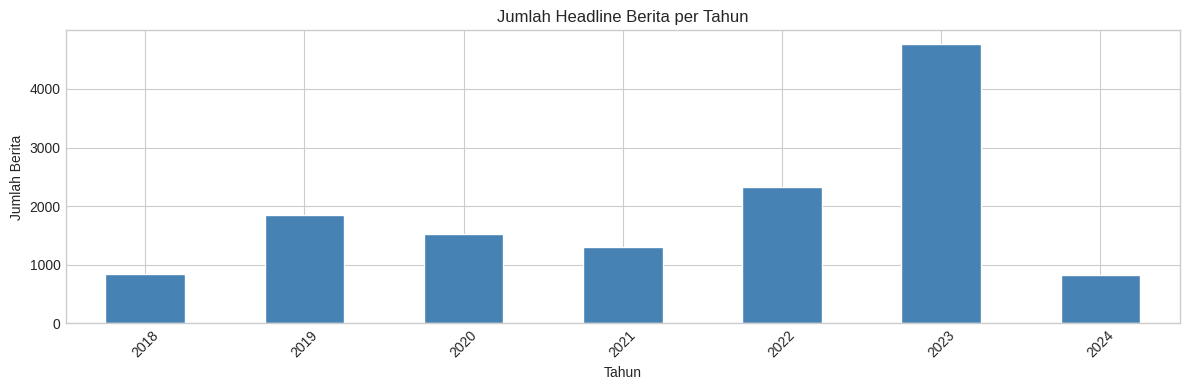

Year
2018     840
2019    1848
2020    1519
2021    1303
2022    2319
2023    4760
2024     833
dtype: int64


In [6]:
df['Year'] = df['Date'].dt.year
news_per_year = df.groupby('Year').size()

fig, ax = plt.subplots(figsize=(12, 4))
news_per_year.plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Jumlah Headline Berita per Tahun')
ax.set_xlabel('Tahun')
ax.set_ylabel('Jumlah Berita')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(news_per_year)

### 3.3 Jumlah Berita per Hari

Rata-rata berita per hari    : 8.78
Maks berita dalam sehari     : 55 (2020-09-23)
Min  berita dalam sehari     : 1 (2018-01-25)


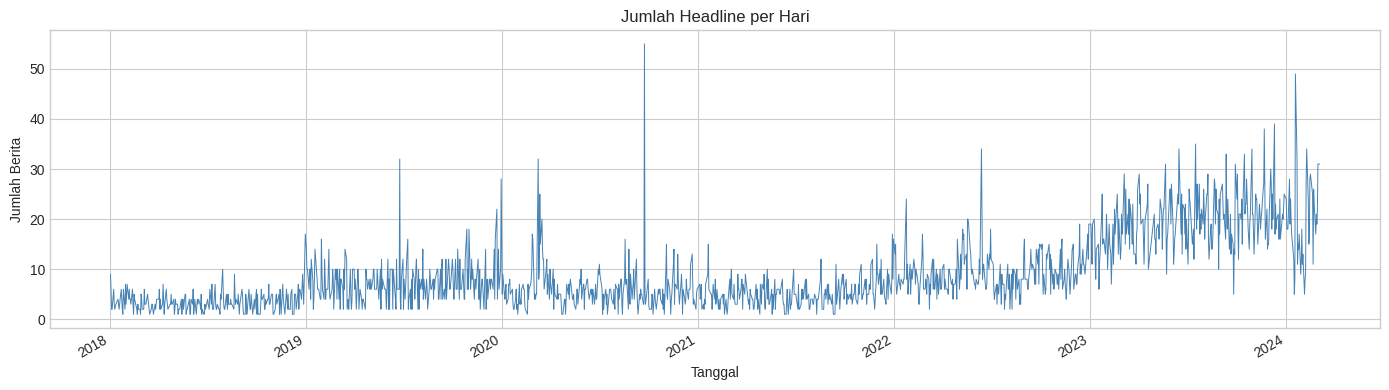

In [7]:
news_per_day = df.groupby('Date').size()
print(f'Rata-rata berita per hari    : {news_per_day.mean():.2f}')
print(f'Maks berita dalam sehari     : {news_per_day.max()} ({news_per_day.idxmax().date()})')
print(f'Min  berita dalam sehari     : {news_per_day.min()} ({news_per_day.idxmin().date()})')

fig, ax = plt.subplots(figsize=(14, 4))
news_per_day.plot(ax=ax, color='steelblue', linewidth=0.7)
ax.set_title('Jumlah Headline per Hari')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Jumlah Berita')
plt.tight_layout()
plt.show()

In [8]:
### 3.4 Distribusi Panjang Headline

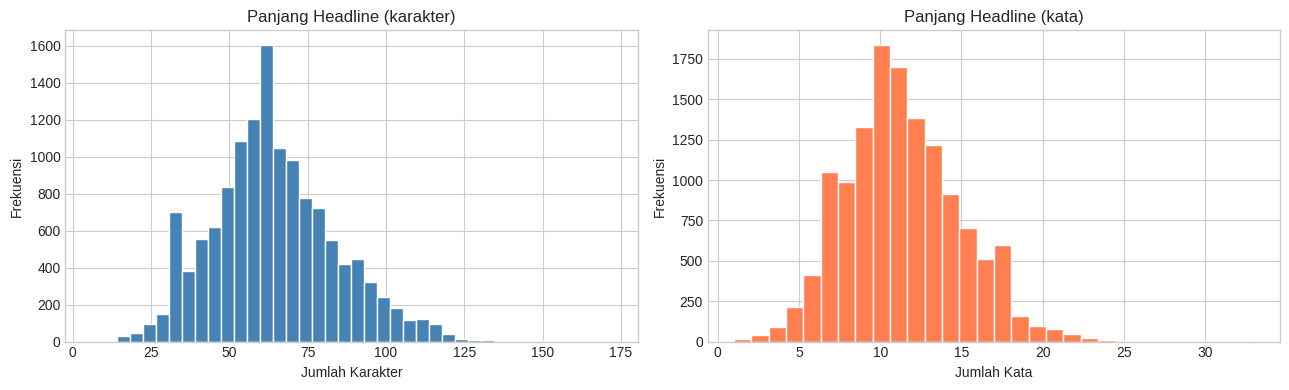

       title_len_char  title_len_word
count        13422.00        13422.00
mean            64.25           11.28
std             19.87            3.47
min              6.00            1.00
25%             51.00            9.00
50%             63.00           11.00
75%             76.00           13.00
max            172.00           33.00


In [9]:
df['title_len_char'] = df['Title'].str.len()
df['title_len_word'] = df['Title'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df['title_len_char'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Panjang Headline (karakter)')
axes[0].set_xlabel('Jumlah Karakter')
axes[0].set_ylabel('Frekuensi')

axes[1].hist(df['title_len_word'], bins=30, color='coral', edgecolor='white')
axes[1].set_title('Panjang Headline (kata)')
axes[1].set_xlabel('Jumlah Kata')
axes[1].set_ylabel('Frekuensi')
plt.tight_layout()
plt.show()
print(df[['title_len_char', 'title_len_word']].describe().round(2))

### 3.5 Closing Price S&P 500

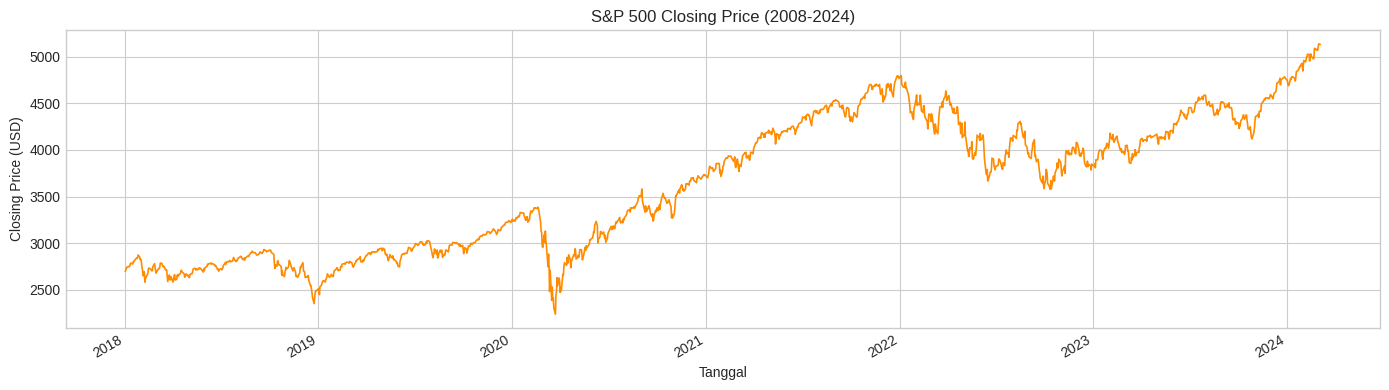

In [10]:
cp_daily = df.groupby('Date')['CP'].first()

fig, ax = plt.subplots(figsize=(14, 4))
cp_daily.plot(ax=ax, color='darkorange', linewidth=1.2)
ax.set_title('S&P 500 Closing Price (2008-2024)')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Closing Price (USD)')
plt.tight_layout()
plt.show()

## 4. Text Preprocessing

### 4.1 Hapus Duplikasi & Missing

In [11]:
print(f'Duplikasi baris    : {df.duplicated().sum()}')
print(f'Duplikasi headline : {df["Title"].duplicated().sum()}')
print(f'Missing Title      : {df["Title"].isnull().sum()}')

df = df.dropna(subset=['Title']).drop_duplicates(subset=['Title']).copy()
print(f'\nShape setelah deduplikasi: {df.shape}')

Duplikasi baris    : 955
Duplikasi headline : 1042
Missing Title      : 0

Shape setelah deduplikasi: (12380, 6)


### 4.2 Normalisasi Teks

In [12]:
def clean_headline(text: str) -> str:
    text = text.strip()
    text = re.sub(r'\s+', ' ', text)          # collapse whitespace
    text = text.encode('ascii', errors='ignore').decode()  # ASCII only
    text = text.replace('""', '"')            # perbaiki kutip ganda hasil CSV
    return text

df['title_clean'] = df['Title'].apply(clean_headline)

changed = df[df['Title'] != df['title_clean']][['Title', 'title_clean']].head(5)
print(f'Baris yang berubah (preview 5):')
print(changed if not changed.empty else '(tidak ada perubahan pada sample)')

Baris yang berubah (preview 5):
                                                                                           Title  \
9   Warren Buffett just won a $1 million bet—and highlighted one of the best ways to grow wealth   
35                              Ford’s most powerful street car ever: New 700 horsepower Mustang   
43              E-mini S&P 500 Index (ES) Futures Technical Analysis – January 19, 2018 Forecast   
59                     Even rising short-term bond yields won’t kill the stock market’s momentum   
79        25th Anniversary Event Held for U.S.-listed SPDR® S&P 500® ETF' | Japan Exchange Group   

                                                                                    title_clean  
9   Warren Buffett just won a $1 million betand highlighted one of the best ways to grow wealth  
35                              Fords most powerful street car ever: New 700 horsepower Mustang  
43              E-mini S&P 500 Index (ES) Futures Technical Analysis  Jan

### 4.3 Filter Headline Terlalu Pendek

In [13]:
MIN_WORDS = 3
mask_short = df['title_clean'].str.split().str.len() < MIN_WORDS
print(f'Headline < {MIN_WORDS} kata: {mask_short.sum()}')
print(df[mask_short]['title_clean'].head())

df = df[~mask_short].copy()
print(f'Shape setelah filter: {df.shape}')

Headline < 3 kata: 14
384                     Wen, Ricky
431                         Pareto
691                   , 64        
988     Cross-Market Consolidation
1420          Buffeted Performance
Name: title_clean, dtype: str
Shape setelah filter: (12366, 7)


## 5. FinBERT Sentiment Scoring

Setiap headline di-score menggunakan model **ProsusAI/finbert** (lokal) yang menghasilkan probabilitas tiga kelas: `positive`, `negative`, `neutral`.  
`sentiment_score` = `positive` − `negative` ∈ [−1, 1] digunakan sebagai fitur kontinu untuk LSTM.

In [14]:
from transformers import pipeline as hf_pipeline
import torch

FINBERT_PATH = Path('../models/finbert/models--ProsusAI--finbert/snapshots/4556d13015211d73dccd3fdd39d39232506f3e43')

device = 0 if torch.cuda.is_available() else -1
print(f'Device : {"GPU" if device == 0 else "CPU"}')

finbert = hf_pipeline(
    task='text-classification',
    model=str(FINBERT_PATH),
    tokenizer=str(FINBERT_PATH),
    device=device,
    top_k=None,       # kembalikan semua 3 skor label sekaligus
    truncation=True,
    max_length=512,
)
print('FinBERT loaded dari local path.')

/home/skripsi_code/stock_prediction/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : GPU


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 54591.41it/s]


FinBERT loaded dari local path.


In [15]:
from tqdm.auto import tqdm

BATCH_SIZE = 32

def score_headlines(texts: list, batch_size: int = BATCH_SIZE) -> pd.DataFrame:
    records = []
    for i in tqdm(range(0, len(texts), batch_size), desc='FinBERT scoring'):
        batch = texts[i : i + batch_size]
        outputs = finbert(batch)          # list[list[dict]]
        for out in outputs:
            scores = {d['label'].lower(): d['score'] for d in out}
            records.append({
                'sentiment_positive': scores.get('positive', 0.0),
                'sentiment_negative': scores.get('negative', 0.0),
                'sentiment_neutral' : scores.get('neutral',  0.0),
                'sentiment_label'   : max(scores, key=scores.get),
                'sentiment_score'   : scores.get('positive', 0.0) - scores.get('negative', 0.0),
            })
    return pd.DataFrame(records)

sentiment_scores = score_headlines(df['title_clean'].tolist())
df = pd.concat([df.reset_index(drop=True), sentiment_scores], axis=1)
print(f'Scoring selesai. Shape: {df.shape}')

FinBERT scoring: 100%|██████████| 387/387 [00:47<00:00,  8.11it/s]

Scoring selesai. Shape: (12366, 12)


In [16]:
print('=== Distribusi Label Sentimen ===')
print(df['sentiment_label'].value_counts())
print(f'\nsentiment_score  mean : {df["sentiment_score"].mean():.4f}')
print(f'sentiment_score  std  : {df["sentiment_score"].std():.4f}')
df[['title_clean', 'sentiment_label', 'sentiment_score',
    'sentiment_positive', 'sentiment_negative', 'sentiment_neutral']].sample(8, random_state=42)

=== Distribusi Label Sentimen ===
sentiment_label
neutral     6171
negative    3562
positive    2633
Name: count, dtype: int64

sentiment_score  mean : -0.0702
sentiment_score  std  : 0.5451


,title_clean,sentiment_label,sentiment_score,sentiment_positive,sentiment_negative,sentiment_neutral
4742,"Cboe Plans to List SPX Tuesday, Thursday-Expiring Weeklys Options",neutral,-0.027968,0.016387,0.044355,0.939259
8233,"Stocks trade mixed at the open, regional bank stocks rally",negative,-0.800541,0.035024,0.835565,0.129412
218,Finance Titan Who Gave $75 Million for Philosophy Studies Says 'More to Come',positive,0.526300,0.554557,0.028257,0.417185
2876,Stock Market Warning: 6 Mega Stocks Dominate S&P 500's $21.4 Trillion Cap,neutral,-0.020331,0.067073,0.087404,0.845523
11862,"World markets today: US stocks surge, S&P 500 hits fresh record high; Netflix climbs over 12% | Mint",positive,0.891404,0.923625,0.032221,0.044153
10277,Market Cycles: S&P 500 Annual Returns Still in Secular Bull Market | investing.com,neutral,-0.159049,0.028661,0.187710,0.783629
2344,Why P/E Ratios Tell You Nothing Right Now,neutral,-0.030977,0.026642,0.057619,0.915740
293,"No, CEOs Don't Make 350 Times More Than Their Employees",neutral,-0.044649,0.033658,0.078307,0.888035


## 6. Agregasi Harian

FinBERT dijalankan per headline. Setelah scoring, skor diagregasi per hari menjadi satu nilai fitur untuk LSTM.

In [17]:
daily = (
    df.groupby('Date')
    .agg(
        headlines       =('title_clean',         list),
        headline_count  =('title_clean',         'count'),
        CP              =('CP',                  'first'),
        sentiment_mean  =('sentiment_score',     'mean'),
        sentiment_pos   =('sentiment_positive',  'mean'),
        sentiment_neg   =('sentiment_negative',  'mean'),
        sentiment_neu   =('sentiment_neutral',   'mean'),
        sentiment_label =('sentiment_label',     lambda x: x.value_counts().index[0]),
    )
    .reset_index()
    .sort_values('Date')
)

print(f'Hari unik: {len(daily)}')
daily[['Date', 'headline_count', 'sentiment_mean', 'sentiment_label', 'CP']].head(5)

Hari unik: 1528


,Date,headline_count,sentiment_mean,sentiment_label,CP
0,2018-01-02,9,0.319749,positive,2695.81
1,2018-01-03,6,0.196713,neutral,2713.06
2,2018-01-04,2,-0.124380,neutral,2723.99
3,2018-01-05,2,0.146174,positive,2743.15
4,2018-01-08,6,0.129192,neutral,2747.71


## 7. Simpan Hasil Preprocessing

In [18]:
# Flat: satu baris per headline + skor sentimen FinBERT
flat_out = DATA_OUT / 'headlines_clean.csv'
df[['Date', 'title_clean',
    'sentiment_label', 'sentiment_score',
    'sentiment_positive', 'sentiment_negative', 'sentiment_neutral',
    'CP']].to_csv(flat_out, index=False)
print(f'Saved flat : {flat_out}  ({len(df)} baris)')

# Harian: agregasi sentimen + CP per hari
daily_out = DATA_OUT / 'headlines_daily_sentiment.csv'
daily[['Date', 'headline_count',
       'sentiment_mean', 'sentiment_pos', 'sentiment_neg', 'sentiment_neu',
       'sentiment_label', 'CP']].to_csv(daily_out, index=False)
print(f'Saved daily: {daily_out}  ({len(daily)} baris)')

Saved flat : ../data/processed/sentiment/headlines_clean.csv  (12366 baris)
Saved daily: ../data/processed/sentiment/headlines_daily_sentiment.csv  (1528 baris)


## 8. Ringkasan

| Langkah | Keterangan |
|---------|------------|
| Load | 19.127 headline (2008–2024) |
| Filter Tahun | Ambil 2018–2024 → 13.422 baris |
| Deduplikasi | Hapus duplikat berdasarkan `Title` |
| Normalisasi | Strip, collapse whitespace, ASCII-only, perbaiki kutip |
| Filter Pendek | Buang headline < 3 kata |
| **FinBERT Scoring** | **Skor `positive/negative/neutral` + `sentiment_score` per headline (lokal)** |
| Agregasi Harian | Mean skor sentimen + modus label per hari |
| Output 1 | `headlines_clean.csv` — flat, per headline + skor sentimen |
| Output 2 | `headlines_daily_sentiment.csv` — agregasi sentimen & CP per hari |

**Langkah selanjutnya:** Gabungkan `headlines_daily_sentiment.csv` dengan fitur OHLCV teknikal sebagai input LSTM (lihat `pipeline/feature_engineering/sentiment_aggregator.py`).